# Pipeline nucleus: De-novo integration vs. mapping with scArches

In [1]:
# import os
# os.chdir('../')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

We use the scArches package here, as it includes scANVI as a dependency, and we will need scArches later anyway when mapping new data to the atlas.

In [2]:
import scanpy as sc
import anndata
import torch
import scarches as sca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [3]:
# sc.settings.set_figure_params(dpi=200, frameon=False)
# sc.set_figure_params(dpi=200)
# sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

In [4]:
sca.__file__

'/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/scarches/__init__.py'

## 0. Import all relevant datasets

First run notebooks in 01_Preparation for nucleus:
- Set labels (cell type harmonization)
- scran normalize counts (not log-transformed!)

query_data:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

source_adata:
- .X: normalized data for hvg calculation (not log-transformed)
- .layers['counts']: raw counts

atlas_data:
- .X: subsetted raw count data for reference atlas (only the 2000 HVGs)

In [5]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/nucleus_labeled_normalized.h5ad")

In [6]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v5.h5ad")

In [7]:
atlas_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")
atlas_data.var.index = atlas_data.var.gene_ids

## 1. Perform de-novo integration

Perform de-novo atlas integration once using the highly variable genes only calculated on the reference and once by recalculating the highly variable genes using both reference and query.

In [ ]:
np.unique(query_data.var.index)

In [ ]:
np.unique(source_adata.var.index)

In [ ]:
print(np.shape(source_adata))
print(np.shape(query_data))

In [8]:
140182+584884

725066

### 1.1 Preparation

In [ ]:
#source_adata.var = source_adata.var.set_index("gene_ids") not applicable, we match on Gene Symbols/names in case of nucleus

Create a combined dataset to use for training the models, consisting of the source and query data.

In [ ]:
combined_data = source_adata.concatenate(query_data, join="outer")

In [ ]:
combined_data.X = np.nan_to_num(combined_data.X, copy=False)

In [ ]:
combined_data.var["highly_variable-0"].fillna(False, inplace=True)

Create two datasets: 
- combined_data: recalculate hvgs and take top 2000
- combined_data_ref_hvg: take 2000 hvg calculated on reference atlas

In [ ]:
combined_data_ref_hvg = combined_data[:,combined_data.var["highly_variable-0"]].copy()

In [ ]:
combined_data_ref_hvg.X = combined_data_ref_hvg.layers['counts'].copy()

Normalized data are only needed for calculation of the highly variable genes. For further learning get back raw counts at first for query data.

In [ ]:
query_data.X = query_data.layers['counts'].copy()

In [ ]:
print(np.shape(combined_data))

Recalculate highly variable genes on reference and query data.

In [22]:
# function to calculate variances on *sparse* matrix
def vars(a, axis=None):
    """ Variance of sparse matrix a
    var = mean(a**2) - mean(a)**2
    """
    a_squared = a.copy()
    a_squared.data **= 2
    return a_squared.mean(axis) - np.square(a.mean(axis))

calculate mean, variance, dispersion per gene:

In [23]:
means = np.mean(combined_data.X, axis=0)

In [24]:
variances = vars(combined_data.X, axis=0)

In [25]:
dispersions = variances / means

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in true_divide
  """Entry point for launching an IPython kernel.


set min_mean cutoff (base this on the plot). We do not want to include the leftmost noisy genes that have high dispersions due to low means.

In [26]:
min_mean = 0.06

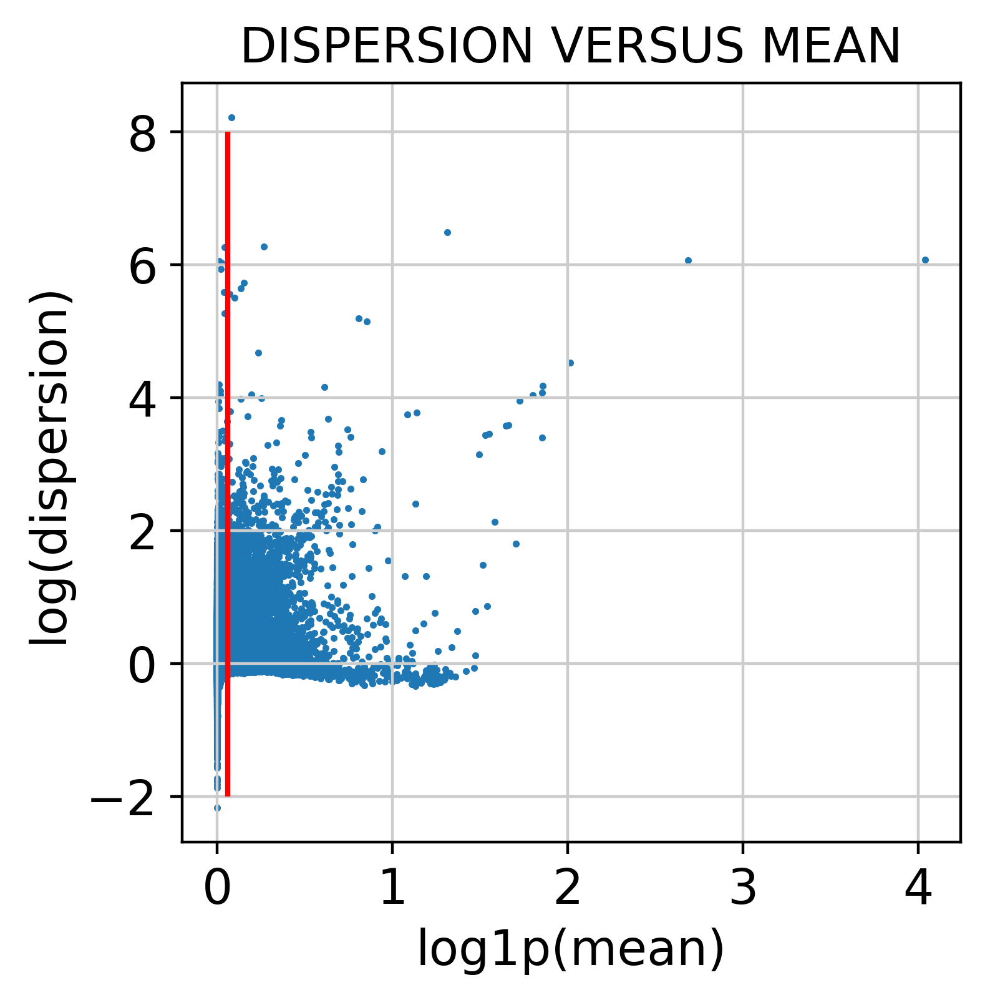

In [27]:
# plot mean versus dispersion plot:
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1,
    
)
plt.vlines(x=np.log1p(min_mean),ymin=-2,ymax=8,color='red')
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

log-transform data:

In [28]:
sc.pp.log1p(combined_data)

now calculate highly variable genes:

In [29]:
sc.pp.highly_variable_genes(combined_data, batch_key="dataset", min_mean=min_mean, flavor="cell_ranger", n_top_genes=2000)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'cells_or_nuclei' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_1' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'gene_ids-0' as categorical
/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7

In [30]:
combined_data.raw = combined_data

Visually check selection of genes:

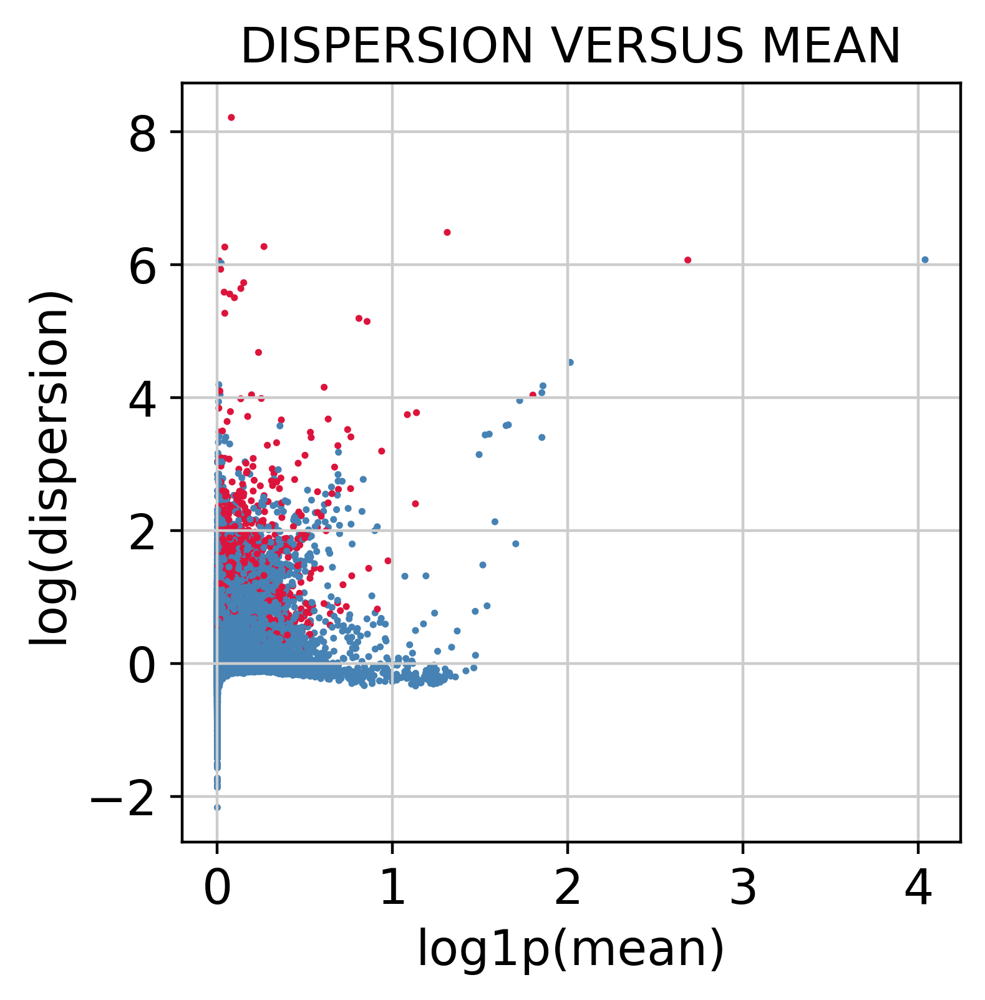

In [31]:
boolean_to_color = {
    True: "crimson",
    False: "steelblue",
}  # make a dictionary that translates the boolean to colors
hvg_colors = combined_data.var.highly_variable.map(boolean_to_color)  # 'convert' the boolean
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1, c=hvg_colors
)
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

Subset data to the calculated top 2000 highly variable genes

In [32]:
combined_data = combined_data[:,combined_data.var.highly_variable].copy()

In [33]:
np.unique(query_data.obs.study)

array(['Duong_lungMAP_unpubl', 'Eils_2020', 'Sun_2020'], dtype=object)

Go back to raw counts

In [34]:
combined_data.X = combined_data.layers["counts"].copy()

In [35]:
np.unique(source_adata.obs.scanvi_label)

array(['AT1', 'AT2', 'B cell lineage', 'Basal', 'Bronchial Vessel 1',
       'Bronchial Vessel 2', 'Dendritic cells', 'EC arterial',
       'EC capillary', 'EC venous', 'Fibroblast lineage',
       'Innate lymphoid cell NK', 'KRT5- KRT17+ epithelial',
       'Lymphatic EC', 'Macrophages', 'Mast cells', 'Megakaryocytes',
       'Mesothelium', 'Monocytes', 'Multiciliated lineage',
       'Neutrophilic', 'Proliferating cells', 'Rare', 'Secretory',
       'Smooth muscle', 'Squamous', 'Submucosal Secretory',
       'T cell lineage', 'unlabeled'], dtype=object)

### 1.2 scVI and scANVI model with newly calculated HVGs

In this section we do a de-novo integration of query and reference, using highly variable genes calculated on joined reference and query data.

Set parameters to use in all scVI and scANVI models. Use standard parameters as provided in scArches tutorial.

In [8]:
condition_key = 'dataset'
cell_type_key = 'scanvi_label'
unlabeled_category = "unlabeled"

scvi_epochs = 500
scanvi_epochs = 200

In [37]:
sca.dataset.setup_anndata(combined_data, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             


Using batches from adata.obs["dataset"]


INFO     Using labels from adata.obs["scanvi_label"]                                         


Using labels from adata.obs["scanvi_label"]


INFO     Using data from adata.X                                                             


...

Computing library size prior per batch


INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 725066 cells, 2000 vars, 20 batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


INFO     Please do not further modify adata until model is trained.                          


Please do not further modify adata until model is trained.


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [38]:
scvi_model = sca.models.SCVI(
    combined_data,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

First train scVI model, which will be used as starting point for scANVI model.

In [39]:
scvi_model.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 500/500: 100%|██████████| 500/500 [7:42:23<00:00, 55.49s/it, loss=529, v_num=1]  


In [40]:
scvi_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scVI")

In [41]:
scvi_model = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scVI", combined_data)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 725066 cells, 2000 vars, 20 batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


Calculate latent embedding of integrated data.

In [42]:
combined_data.obsm["X_scVI"] = scvi_model.get_latent_representation()

In [43]:
sc.pp.neighbors(combined_data, use_rep="X_scVI")
sc.tl.leiden(combined_data)
sc.tl.umap(combined_data)

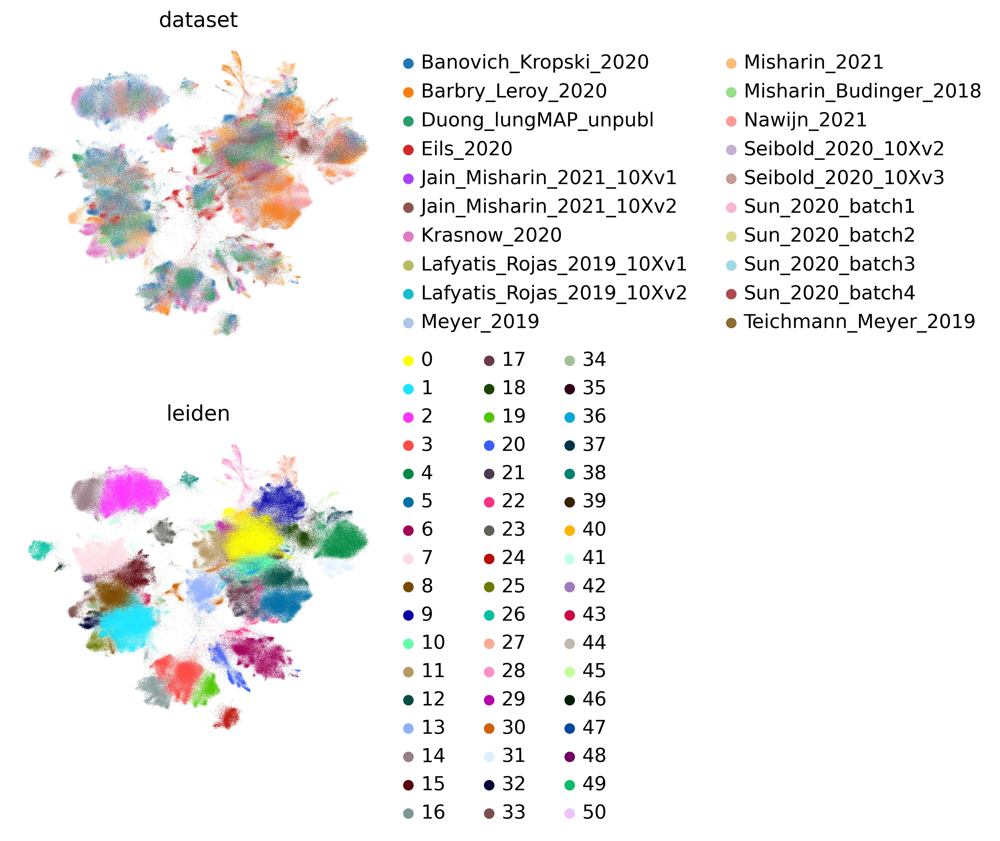

In [44]:
sc.pl.umap(
    combined_data,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

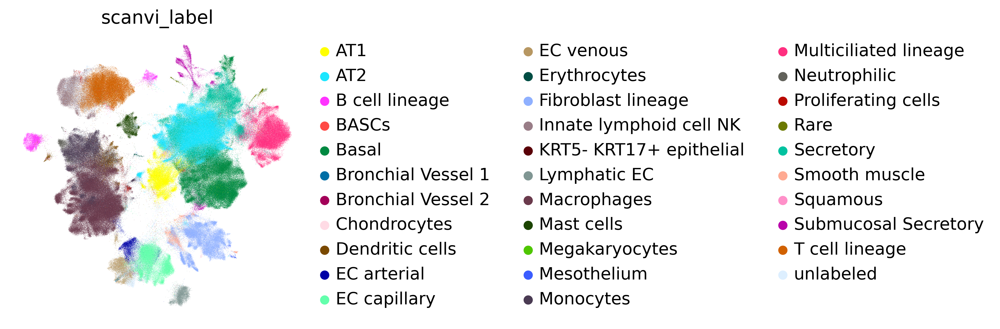

In [45]:
sc.pl.umap(combined_data, color=cell_type_key, frameon=False)

Build scANVI model ontop of scVI model. Therefore load scVI model and then train scANVI model based on it, now including cell type annotations information.

In [46]:
scANVI_model = sca.models.SCANVI.from_scvi_model(scvi_model, unlabeled_category, adata=combined_data)

In [47]:
scANVI_model.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 199/200: 100%|█████████▉| 199/200 [6:45:42<02:02, 122.32s/it, loss=647, v_num=1]  


In [48]:
scANVI_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scANVI")

In [49]:
#scANVI_model = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI", combined_data)

In [50]:
print("Labelled Indices: ", len(scANVI_model._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model._unlabeled_indices))

Labelled Indices:  693918
Unlabelled Indices:  31148


Predict cell type annotations and calculate the latent embedding of the integrated data.

In [51]:
combined_data.obs["C_scANVI"] = scANVI_model.predict(combined_data)
combined_data.obsm["X_scANVI"] = scANVI_model.get_latent_representation(combined_data)

In [52]:
sc.pp.neighbors(combined_data, use_rep="X_scANVI")
sc.tl.umap(combined_data)

... storing 'age' as categorical
... storing 'highly_variable_intersection-0' as categorical


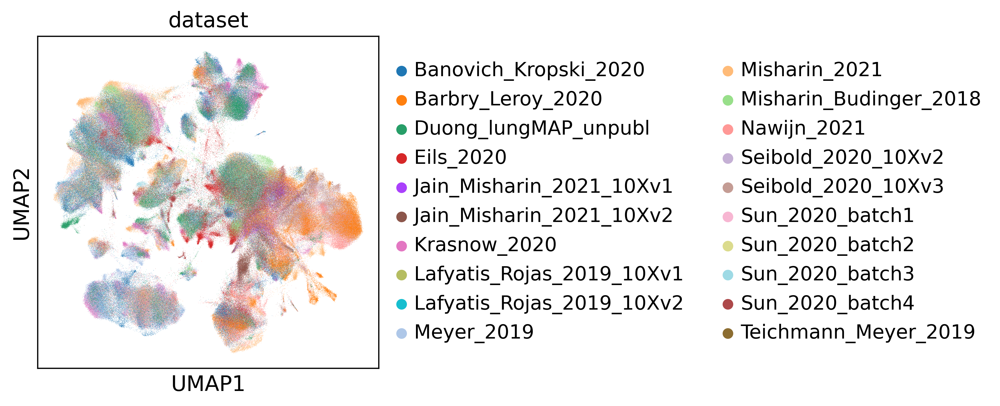

In [6]:
sc.pl.umap(combined_data, color="dataset")

... storing 'C_scANVI' as categorical


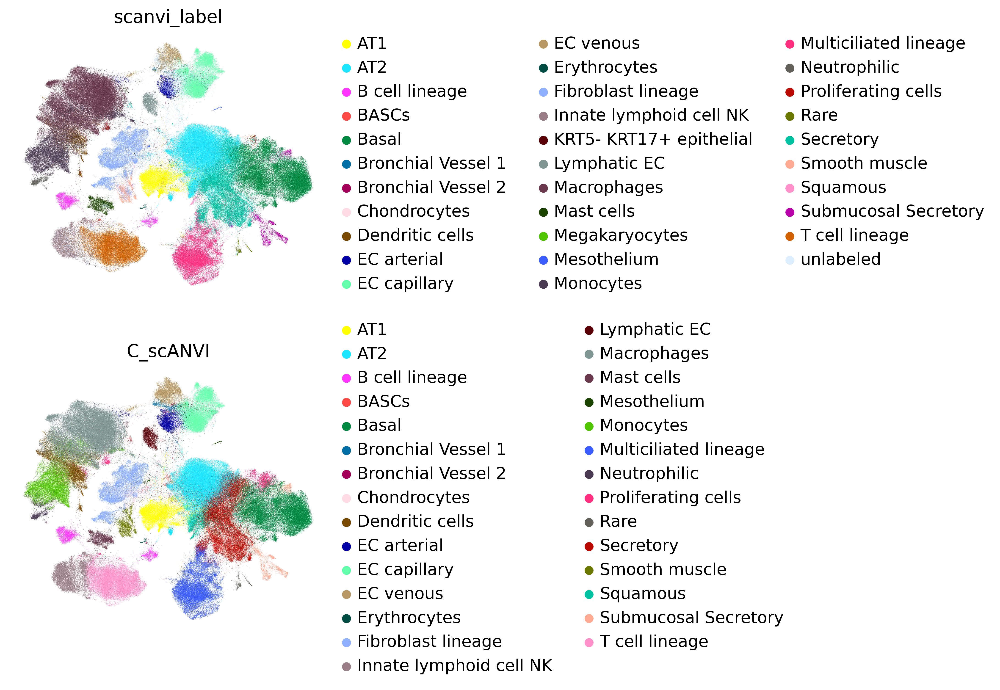

In [53]:
sc.pl.umap(combined_data, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

Calculate and plot a confusion matrix.

In [54]:
df = combined_data.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

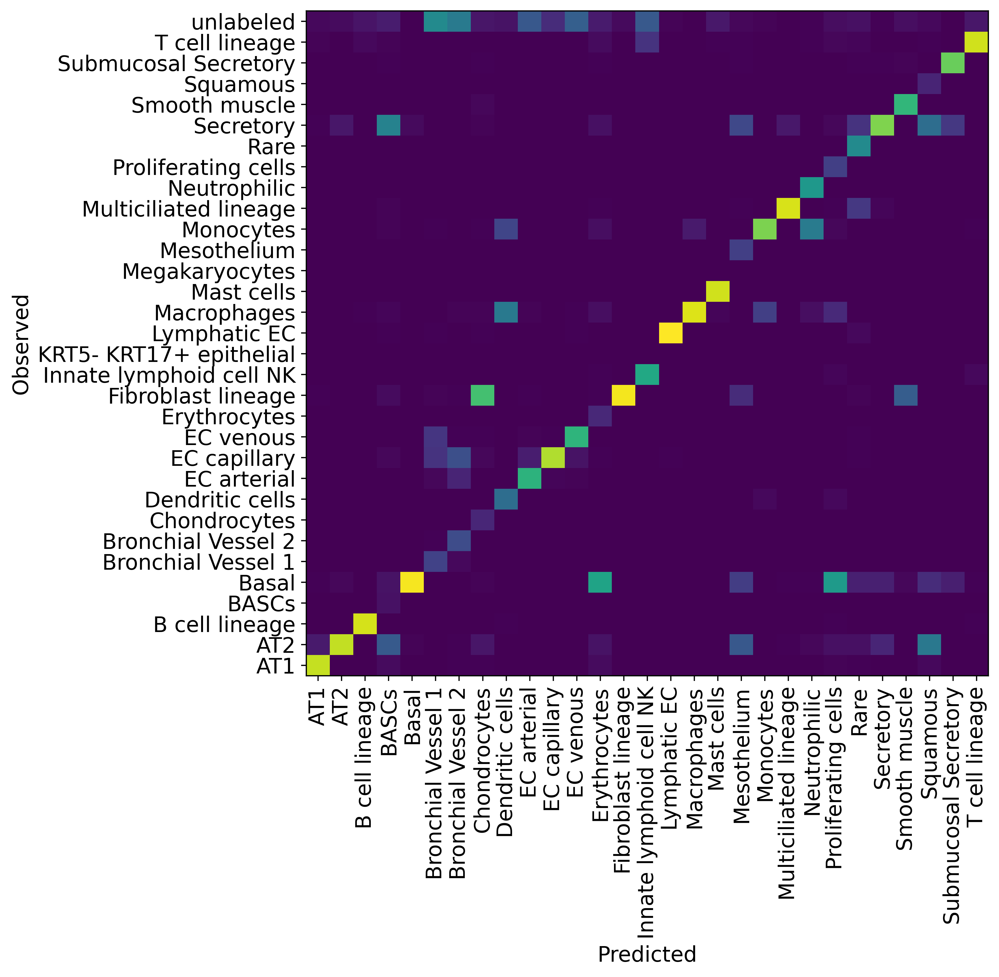

In [55]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [56]:
combined_data.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_denovo.h5ad")

### 1.3 scVI and scANVI model with old reference HVGs

In this section we do a de-novo integration of query and reference, using the highly variable genes calculated only on the reference data.

In [57]:
sca.dataset.setup_anndata(combined_data_ref_hvg, batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             


Using batches from adata.obs["dataset"]


INFO     Using labels from adata.obs["scanvi_label"]                                         


Using labels from adata.obs["scanvi_label"]


INFO     Using data from adata.X                                                             


...

Computing library size prior per batch


INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 725066 cells, 2000 vars, 20 batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


INFO     Please do not further modify adata until model is trained.                          


Please do not further modify adata until model is trained.


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [58]:
scvi_model_ref_hvg = sca.models.SCVI(
    combined_data_ref_hvg,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

First train scVI model, which will be used as starting point for scANVI model.

In [59]:
scvi_model_ref_hvg.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 500/500: 100%|██████████| 500/500 [9:11:04<00:00, 66.13s/it, loss=590, v_num=1]  


In [60]:
scvi_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scVI_ref_hvg")

In [22]:
scvi_model_ref_hvg = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 725066 cells, 2000 vars, 20 batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


Calculate latent embedding of integrated data.

In [23]:
combined_data_ref_hvg.obsm["X_scVI"] = scvi_model_ref_hvg.get_latent_representation()

In [63]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scVI")
sc.tl.leiden(combined_data_ref_hvg)
sc.tl.umap(combined_data_ref_hvg)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'cells_or_nuclei' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_1' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical


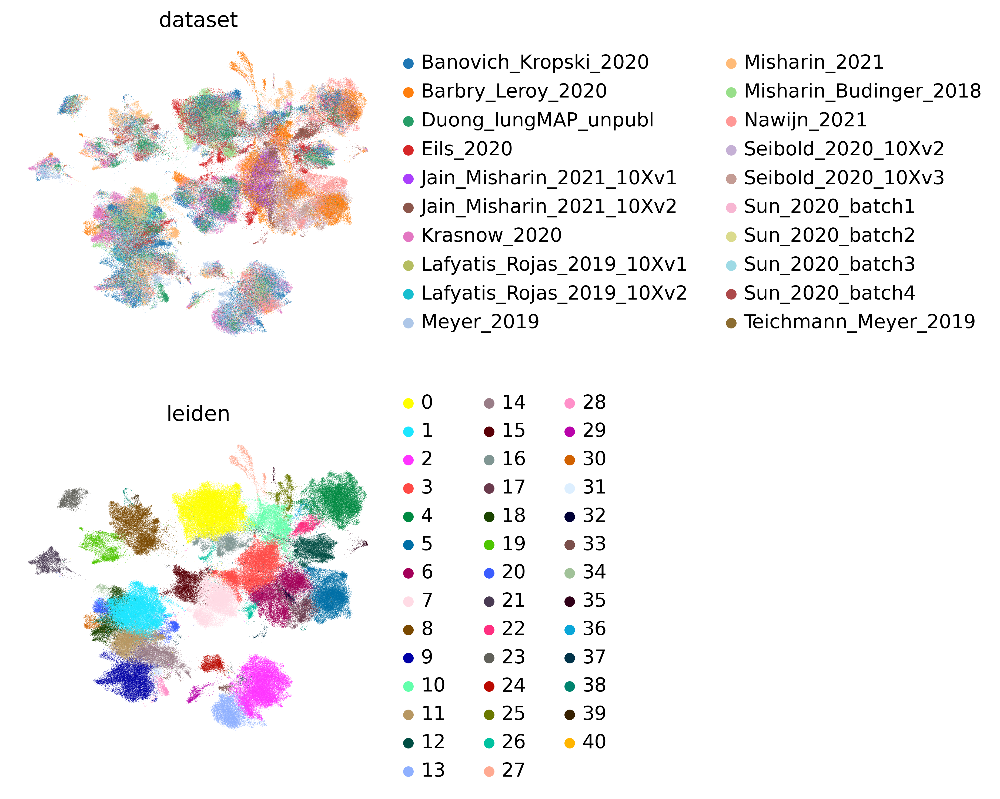

In [64]:
sc.pl.umap(
    combined_data_ref_hvg,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

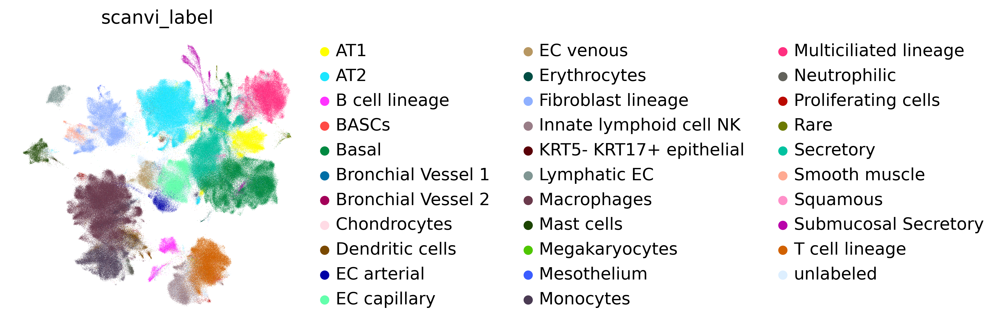

In [65]:
sc.pl.umap(combined_data_ref_hvg, color=cell_type_key, frameon=False)

Build scANVI model ontop of scVI model. Therefore load scVI model and then train scANVI model based on it, now including cell type annotations information.

In [26]:
scANVI_model_ref_hvg = sca.models.SCANVI.from_scvi_model(scvi_model_ref_hvg, unlabeled_category, adata=combined_data_ref_hvg)

In [ ]:
scANVI_model_ref_hvg.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 114/200:  56%|█████▋    | 113/200 [6:08:32<4:40:11, 193.24s/it, loss=684, v_num=1]

In [ ]:
scANVI_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scANVI_ref_hvg")

In [24]:
scANVI_model_ref_hvg = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/scANVI_ref_hvg", combined_data_ref_hvg)

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 725066 cells, 2000 vars, 20 batches, 32 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [25]:
print("Labelled Indices: ", len(scANVI_model_ref_hvg._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model_ref_hvg._unlabeled_indices))

Labelled Indices:  693918
Unlabelled Indices:  31148


Predict cell type annotations and calculate the latent embedding of the integrated data.

In [26]:
combined_data_ref_hvg.obs["C_scANVI"] = scANVI_model_ref_hvg.predict(combined_data_ref_hvg)
combined_data_ref_hvg.obsm["X_scANVI"] = scANVI_model_ref_hvg.get_latent_representation(combined_data_ref_hvg)

In [27]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scANVI")
sc.tl.umap(combined_data_ref_hvg)

... storing 'age' as categorical
... storing 'highly_variable_intersection-0' as categorical


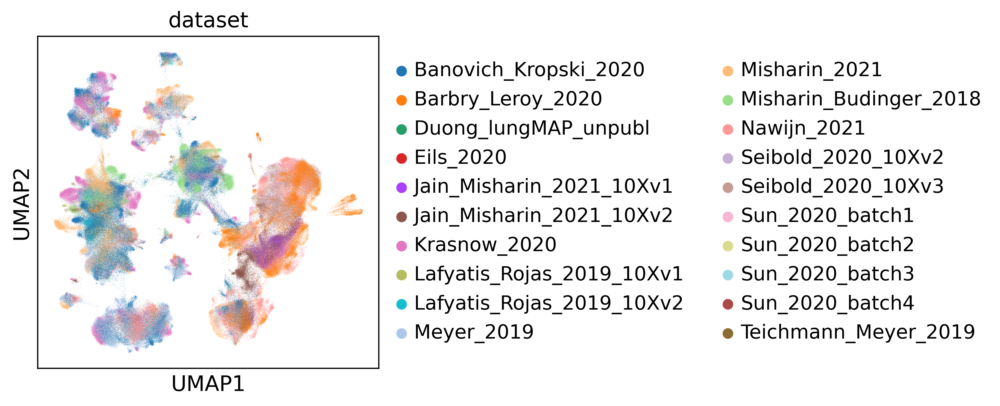

In [11]:
sc.pl.umap(combined_data_ref_hvg, color="dataset")

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'cells_or_nuclei' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_1' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'C_scANVI' as categorical


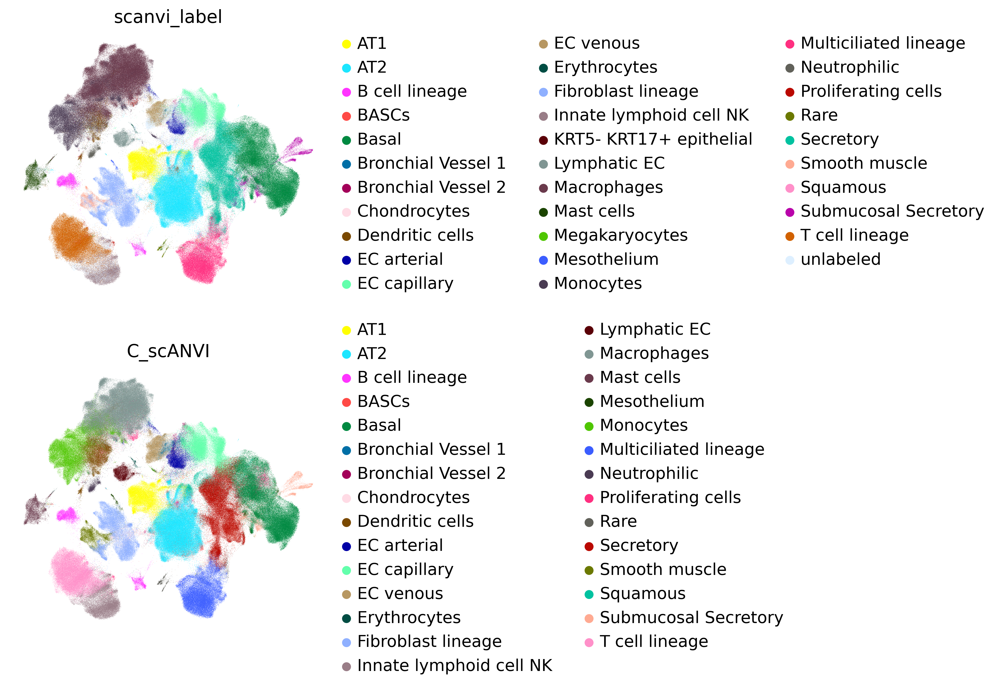

In [28]:
sc.pl.umap(combined_data_ref_hvg, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

Calculate and plot a confusion matrix.

In [29]:
df = combined_data_ref_hvg.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

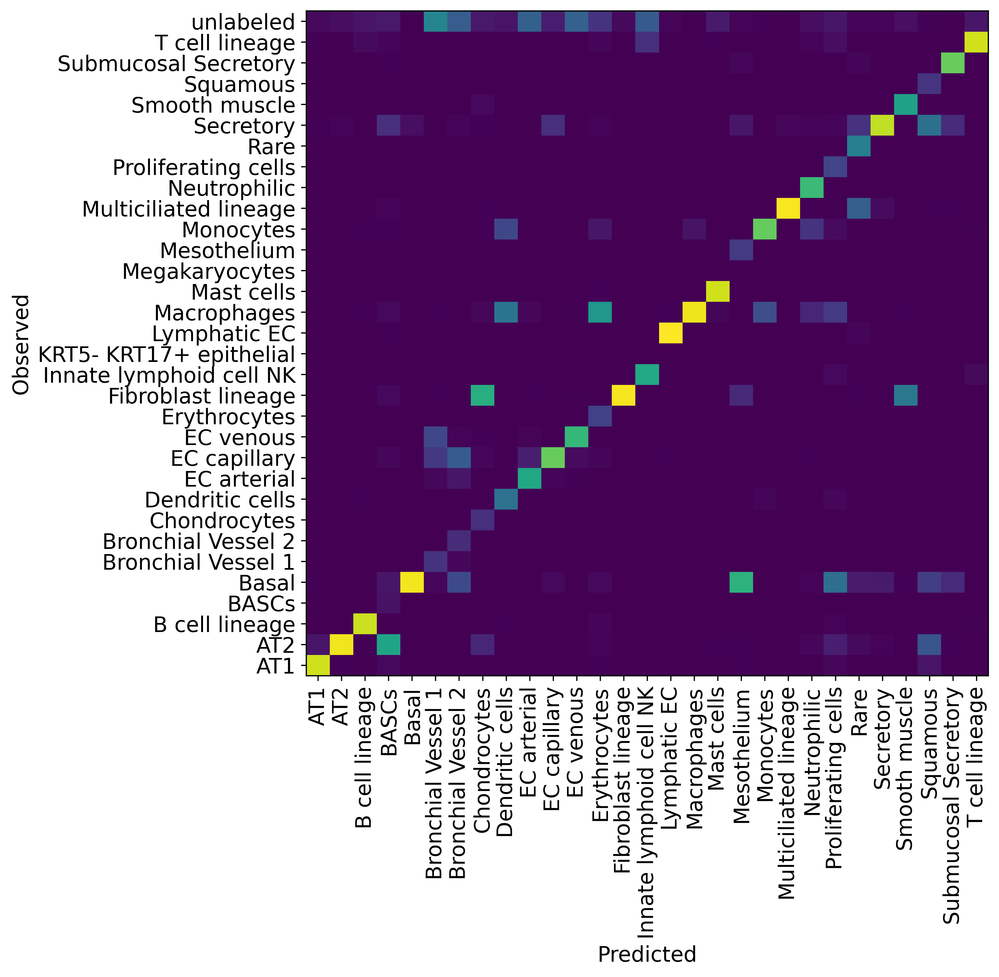

In [30]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [31]:
combined_data_ref_hvg.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_denovo_ref_hvg.h5ad")

## 2. scArches | Perform surgery 

In this section we will use the transfer learning approach/model scArches to integrate reference and query data.

### 2.1 Unlabeled scArches

Use scArches without the information of the labels. Therefore set all labels of query to "unlabeled".

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

The nucleus query data is missing some genes which are included in the reference, therefor define function which adds the missing genes and pads them with zeros.

In [9]:
def subset_and_pad_adata(gene_set, adata):
    """
    This function uses a gene list provided as a Pandas dataframe with gene symbols and
    Ensembl IDs and subsets a larger Anndata object to only the genes in this list. If
    Not all genes are found in the AnnData object, then zero-padding is performed.
    """
    # Example inputs:
    # genes_filename = '/storage/groups/ml01/workspace/hlca_lisa.sikkema_malte.luecken/genes_for_mapping.csv'
    # data_filename = '/storage/groups/ml01/workspace/hlca_lisa.sikkema_malte.luecken/ready/adams.h5ad'
    # gene_set = pd.read_csv(genes_filename)
    # adata = sc.read(data_filename)

    # Prep objects
    if 'gene_symbols' in gene_set.columns:
        gene_set.index = gene_set['gene_symbols']

    else:
        raise ValueError('The input gene list was not of the expected type!\n'
                         'Gene symbols and ensembl IDs are expected in column names:\n'
                         '\t`gene_symbols` and `Unnamed: 0`')

    # Subset adata object
    common_genes = [gene for gene in gene_set['gene_symbols'].values if gene in adata.var_names]
    if len(common_genes) == 0:
        print("WARNING: YOU SHOULD PROBABLY SWITCH YOUR ADATA.VAR INDEX COLUMN TO GENE NAMES"
                  " RATHER THAN IDS! No genes were recovered.")
        return

    adata_sub = adata[:,common_genes].copy()
    adata_sub.var["gene_symbols"] = adata_sub.var.index

    # Pad object with 0 genes if needed
    if len(common_genes) < len(gene_set):
        diff = len(gene_set) - len(common_genes)
        print(f'not all genes were recovered, filling in 0 counts for {diff} missing genes...')
        
        # Genes to pad with
        genes_to_add = set(gene_set['gene_symbols'].values).difference(set(adata_sub.var_names))
        new_var = gene_set.loc[genes_to_add]
        
        if 'Unnamed: 0' in new_var.columns:
            # Assumes the unnamed column are ensembl values
            new_var['ensembl'] = new_var['Unnamed: 0']
            del new_var['Unnamed: 0']

        df_padding = pd.DataFrame(data=np.zeros((adata_sub.shape[0],len(genes_to_add))), index=adata_sub.obs_names, columns=new_var.index)
        adata_padding = sc.AnnData(df_padding, var=new_var)
        
        # Concatenate object
        adata_sub = anndata.concat([adata_sub, adata_padding], axis=1, join='inner', index_unique=None, merge='unique')

    # Ensure ensembl IDs are available
    #adata_sub.var['ensembl'] = gene_set['Unnamed: 0']

    return adata_sub

In [10]:
scANVI_model_original = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI", atlas_data)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Prepare query data for scArches: set all labels to unlabeled

In [11]:
query_data.obs["scanvi_label_original"]=query_data.obs["scanvi_label"]

In [12]:
query_data.obs["scanvi_label"]=scANVI_model_original.unlabeled_category_

In [13]:
#Calculate gene overlap between atlas and query
len((set(atlas_data.var.index)).difference(set(query_data.var.index)))/len(set(atlas_data.var.index))

1.0

In [14]:
atlas_genes = atlas_data.var[["gene_symbols","gene_ids"]]

In [15]:
# Add all genes that are in the atlas but not in the query and pad them with 0s
query_data_padded = subset_and_pad_adata(atlas_genes, query_data)

not all genes were recovered, filling in 0 counts for 42 missing genes...


In [16]:
atlas_data.var.index = atlas_data.var.gene_symbols

For scArches the genes in reference and query have to be the same and in the same order.

In [17]:
query_data_scArches = query_data_padded[:,atlas_data.var.index].copy()

scArches model is build on top of scANVI model of the original reference atlas.

In [41]:
scArches_model = sca.models.SCANVI.load_query_data(
    query_data_scArches,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model._unlabeled_indices = np.arange(query_data_scArches.n_obs)
scArches_model._labeled_indices = []
print("Labelled Indices: ", len(scArches_model._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model._unlabeled_indices))

INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 140182 cells, 2000 vars, 20       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 140182 cells, 2000 vars, 20 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


Labelled Indices:  0
Unlabelled Indices:  140182


In [42]:
scArches_model.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))

INFO     Training for 200 epochs.                                                            


Training for 200 epochs.
GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [38:28<00:00, 11.54s/it, loss=612, v_num=1]


Concatenate original reference atlas and the newly learned query atlas to get one common representation. For this, predict the cell type annotations and calculate the latent representation of the integration.

In [43]:
query_data_scArches_full = atlas_data.concatenate(query_data_scArches)
query_data_scArches_full.obs["C_scArches"] = scArches_model.predict(query_data_scArches_full)
query_data_scArches_full.obsm["X_scArches"] = scArches_model.get_latent_representation(query_data_scArches_full)

INFO     Input adata not setup with scvi. attempting to transfer anndata setup               


Input adata not setup with scvi. attempting to transfer anndata setup


INFO     Using data from adata.X                                                             


Using data from adata.X


INFO     Computing library size prior per batch                                              


Computing library size prior per batch


INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     


Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']


INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


Successfully registered anndata object containing 725066 cells, 2000 vars, 20 batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates and 0 extra continuous covariates.


In [44]:
sc.pp.neighbors(query_data_scArches_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_full)

... storing 'age' as categorical


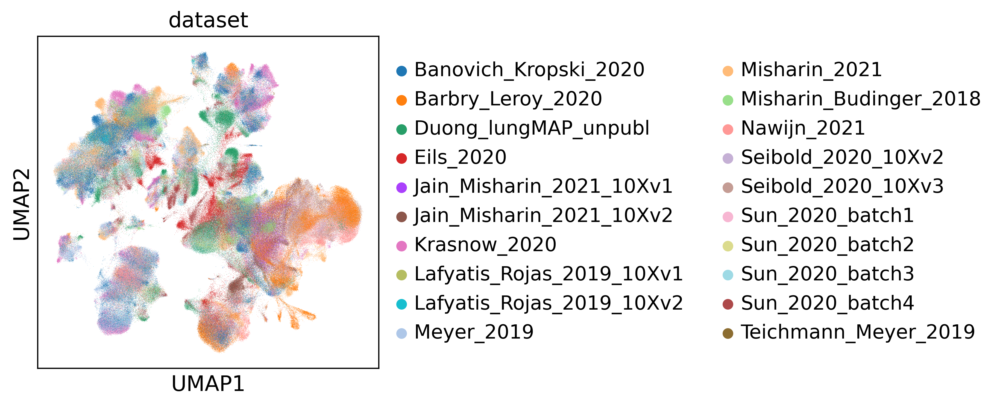

In [13]:
sc.pl.umap(query_data_scArches_full,color="dataset")

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'cells_or_nuclei' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_1' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'C_scArches' as categorical


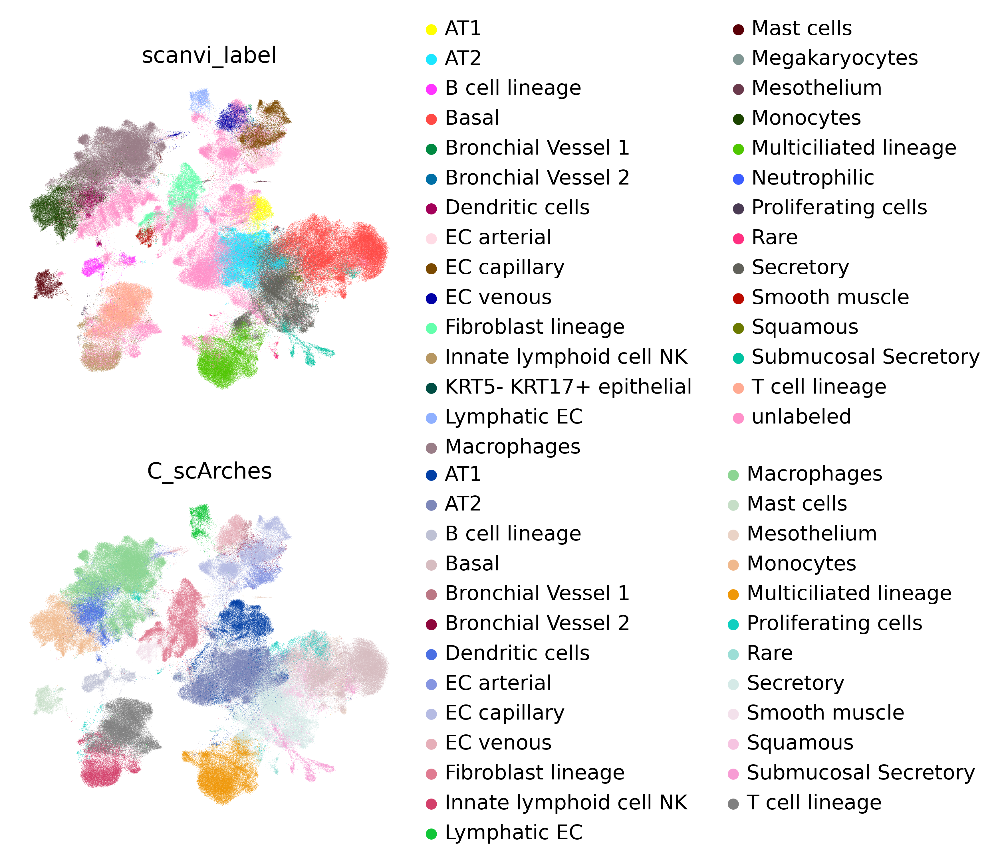

In [45]:
sc.pl.umap(query_data_scArches_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

Calculate and plot a confusion matrix.

In [46]:
df = query_data_scArches_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

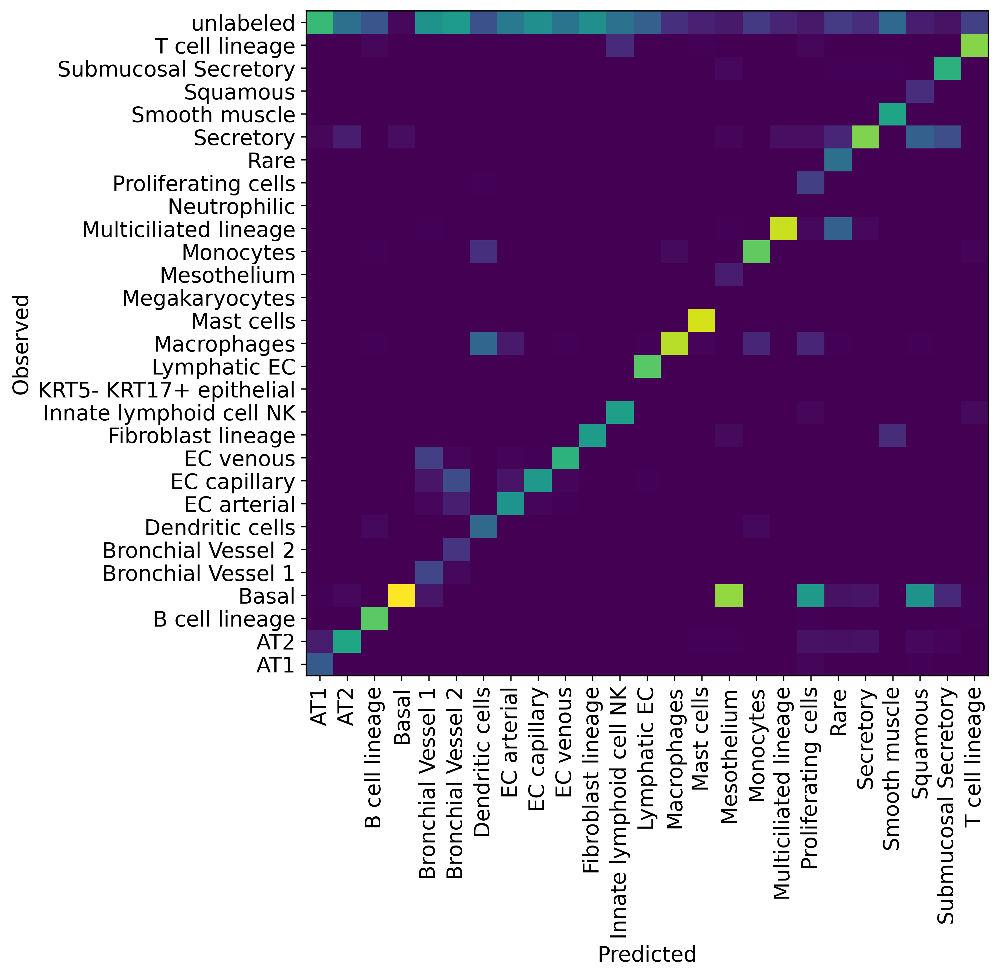

In [47]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [48]:
query_data_scArches_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_scArches_full.h5ad")

### 2.2 Labeled scArches

Use scArches with the information of the labels. Make sure that all labels in the query data are contained in the original reference atlas, if not, set them to "unlabeled".

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set labels to unlabeled which are not in the atlas

In [18]:
mask_unlabeled = [x for x in set(query_data.obs.scanvi_label_original) if x not in set(atlas_data.obs.scanvi_label)]

In [19]:
set(query_data.obs.scanvi_label_original)

{'AT1',
 'AT2',
 'B cell lineage',
 'BASCs',
 'Basal',
 'Bronchial Vessel 1',
 'Chondrocytes',
 'Dendritic cells',
 'EC arterial',
 'EC capillary',
 'EC venous',
 'Erythrocytes',
 'Fibroblast lineage',
 'Innate lymphoid cell NK',
 'Lymphatic EC',
 'Macrophages',
 'Mast cells',
 'Monocytes',
 'Multiciliated lineage',
 'Neutrophilic',
 'Rare',
 'Secretory',
 'Smooth muscle',
 'Submucosal Secretory',
 'T cell lineage',
 'unlabeled'}

In [20]:
set(atlas_data.obs.scanvi_label)

{'AT1',
 'AT2',
 'B cell lineage',
 'Basal',
 'Bronchial Vessel 1',
 'Bronchial Vessel 2',
 'Dendritic cells',
 'EC arterial',
 'EC capillary',
 'EC venous',
 'Fibroblast lineage',
 'Innate lymphoid cell NK',
 'KRT5- KRT17+ epithelial',
 'Lymphatic EC',
 'Macrophages',
 'Mast cells',
 'Megakaryocytes',
 'Mesothelium',
 'Monocytes',
 'Multiciliated lineage',
 'Neutrophilic',
 'Proliferating cells',
 'Rare',
 'Secretory',
 'Smooth muscle',
 'Squamous',
 'Submucosal Secretory',
 'T cell lineage',
 'unlabeled'}

In [21]:
mask_unlabeled

['BASCs', 'Chondrocytes', 'Erythrocytes']

In [32]:
query_data_padded.obs["scanvi_label"][query_data_padded.obs["scanvi_label_original"].isin(mask_unlabeled)] = scANVI_model_original.unlabeled_category_

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [33]:
query_data_padded.obs["scanvi_label"][~query_data_padded.obs["scanvi_label_original"].isin(mask_unlabeled)] = query_data_padded.obs["scanvi_label_original"][~query_data_padded.obs["scanvi_label_original"].isin(mask_unlabeled)]

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [34]:
query_data_scArches_labeled = query_data_padded[:,atlas_data.var.index].copy()

In [35]:
[x for x in set(query_data_scArches_labeled.obs.scanvi_label) if x not in set(atlas_data.obs.scanvi_label)]
# if empty set, then all labels in query data are in atlas data contained

[]

scArches model is build on top of scANVI model of the original reference atlas.

In [38]:
scArches_model_labeled = sca.models.SCANVI.load_query_data(
    query_data_scArches_labeled,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model_labeled._unlabeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]==scArches_model_labeled.unlabeled_category_))[0]
scArches_model_labeled._labeled_indices = list(np.where(query_data_scArches_labeled.obs["scanvi_label"]!=scArches_model_labeled.unlabeled_category_))[0]
print("Labelled Indices: ", len(scArches_model_labeled._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model_labeled._unlabeled_indices))

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 140182 cells, 2000 vars, 20       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
Labelled Indices:  132380
Unlabelled Indices:  7802


In [39]:
scArches_model_labeled.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [44:43<00:00, 13.42s/it, loss=804, v_num=1]


Concatenate original reference atlas and the newly learned query atlas to get one common representation. For this, predict the cell type annotations and calculate the latent representation of the integration.

In [40]:
query_data_scArches_labeled_full = atlas_data.concatenate(query_data_scArches_labeled)
query_data_scArches_labeled_full.obs["C_scArches"] = scArches_model_labeled.predict(query_data_scArches_labeled_full)
query_data_scArches_labeled_full.obsm["X_scArches"] = scArches_model_labeled.get_latent_representation(query_data_scArches_labeled_full)

INFO     Input adata not setup with scvi. attempting to transfer anndata setup               
INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 725066 cells, 2000 vars, 20       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [41]:
sc.pp.neighbors(query_data_scArches_labeled_full, use_rep="X_scArches")
sc.tl.umap(query_data_scArches_labeled_full)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study' as categorical
... storing 'subject_ID' as categorical
... storing 'sex' as categorical
... storing 'ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'condition' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'cells_or_nuclei' as categorical
... storing 'single_cell_platform' as categorical
... storing 'dataset' as categorical
... storing 'anatomical_region_level_1' as categorical
... storing 'scanvi_label' as categorical
... storing 'ann_level_1' as categorical
... storing 'ann_level_2' as categorical
... storing 'ann_level_3' as categorical
... storing 'ann_level_4' as categorical
... storing 'ann_level_5' as categorical
... storing 'C_scArches' as categorical


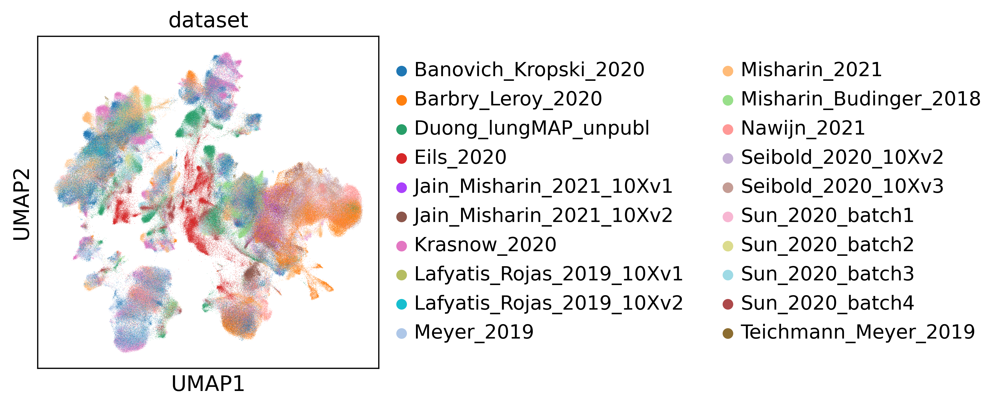

In [42]:
sc.pl.umap(query_data_scArches_labeled_full, color="dataset")

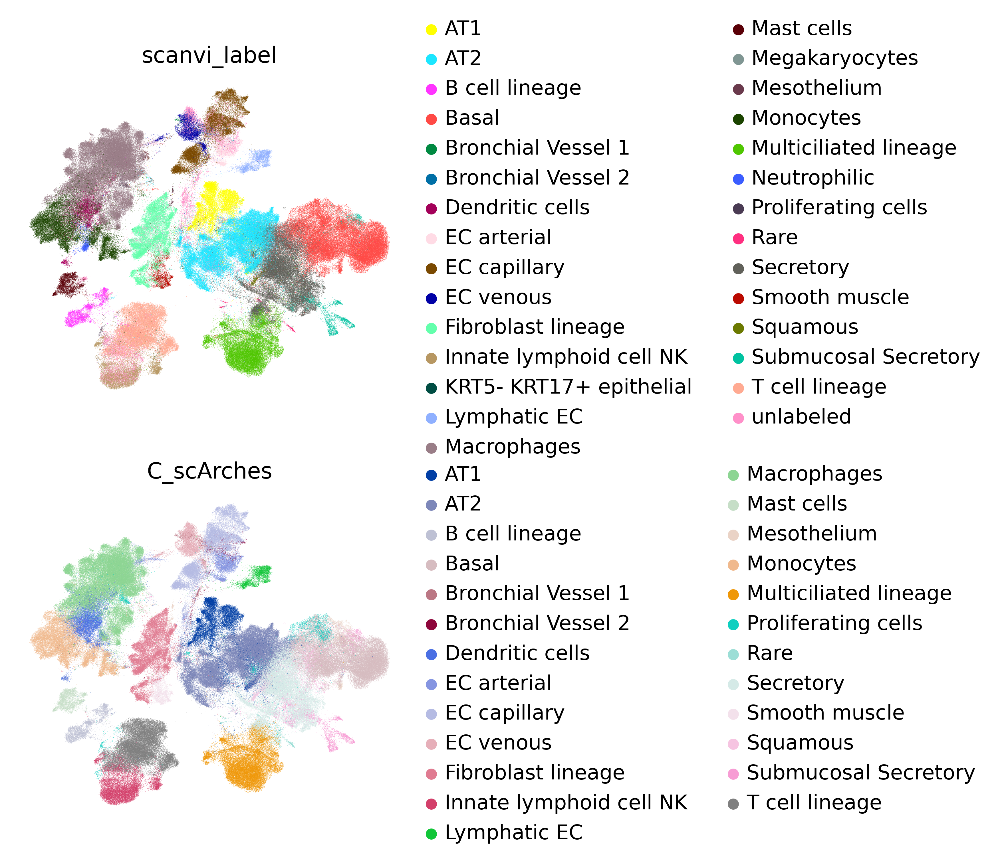

In [43]:
sc.pl.umap(query_data_scArches_labeled_full, color=["scanvi_label", "C_scArches"], ncols=1, frameon=False)

Calculate and plot confusion matrix.

In [44]:
df = query_data_scArches_labeled_full.obs.groupby(["scanvi_label", "C_scArches"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

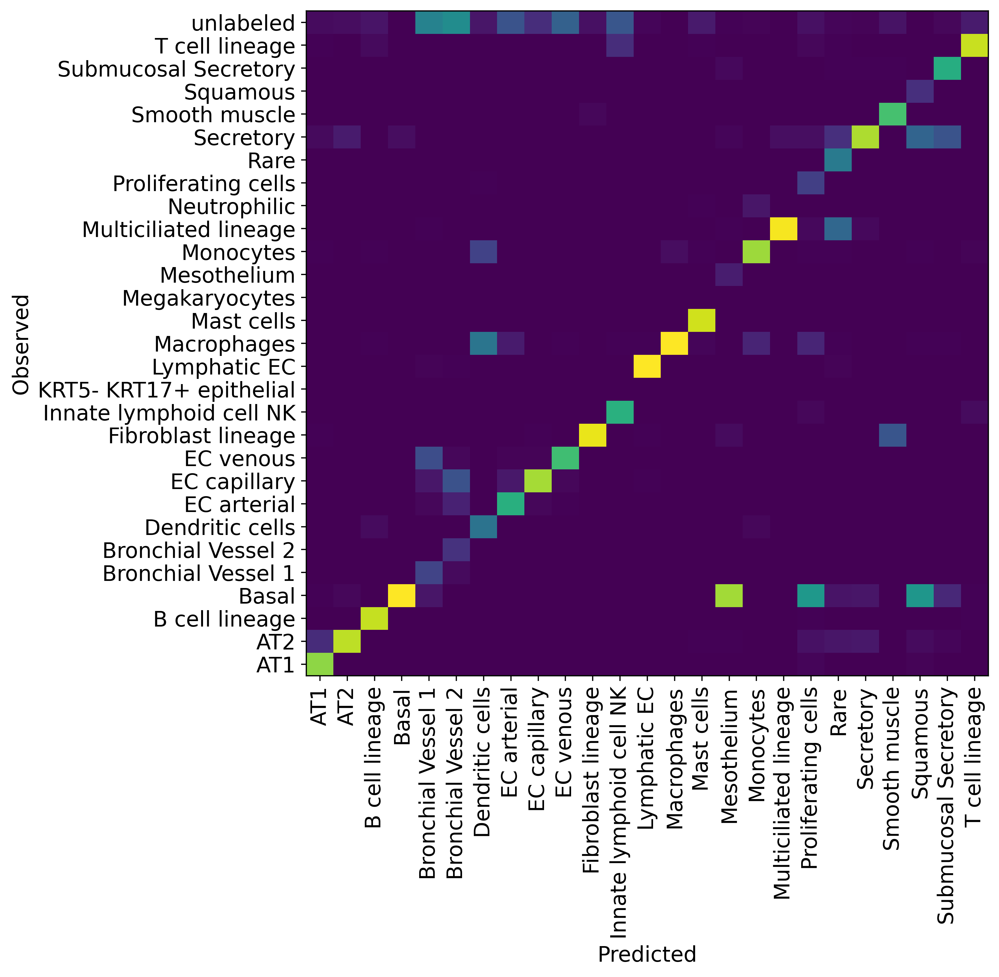

In [45]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [46]:
query_data_scArches_labeled_full.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/nucleus/learned_atlas/nucleus_atlas_scArches_labeled_full_II.h5ad")

In [15]:
sc.logging.print_versions()

The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.7.6
scanpy      1.8.1
sinfo       0.3.4
-----
PIL                         8.3.1
absl                        NA
anyio                       NA
attr                        21.2.0
babel                       2.9.1
backcall                    0.2.0
beta_ufunc                  NA
binom_ufunc                 NA
bottleneck                  1.3.2
brotli                      NA
certifi                     2021.10.08
cffi                        1.14.6
chardet                     4.0.0
charset_normali